# Market-Risk VaR Engine — Day 2
## Value at Risk (three methods) + Expected Shortfall

Day 1 produced the daily portfolio **P&L series**. Today we turn it into the
core risk numbers a market-risk desk reports:

- **VaR** by three standard methods — historical, parametric, Monte Carlo
- **Expected Shortfall (ES)** — the FRTB successor to VaR

**What VaR means.** A 1-day 99% VaR of \$X means: on 99% of days the loss
should be smaller than \$X; only ~1% of days should be worse. It's the
headline number banks use to size market-risk capital.


In [1]:
import numpy as np
import pandas as pd
from scipy import stats

np.random.seed(42)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## Rebuild the Day 1 P&L

So this notebook is self-contained, we rebuild the book and P&L exactly as in
Day 1 (real Yahoo data if available, realistic synthetic fallback otherwise).


In [2]:
PORTFOLIO = {
    "AAPL": (1_000_000, +1), "JPM": (750_000, +1), "SPY": (2_000_000, -1),
    "FXE": (1_500_000, +1), "FXY": (1_000_000, -1), "TLT": (1_250_000, +1),
}
START_DATE, END_DATE = "2019-01-01", "2024-12-31"

def signed_notionals():
    return pd.Series({t: n * d for t, (n, d) in PORTFOLIO.items()})

def make_synthetic_prices():
    dates = pd.bdate_range(START_DATE, END_DATE); n = len(dates)
    ann_vol = {"AAPL":0.30,"JPM":0.28,"SPY":0.18,"FXE":0.08,"FXY":0.10,"TLT":0.13}
    beta = {"AAPL":1.1,"JPM":1.0,"SPY":1.0,"FXE":0.1,"FXY":-0.1,"TLT":-0.3}
    market = np.random.normal(0, 0.01, n)
    rets = {t: beta[t]*market + np.random.normal(0, ann_vol[t]/np.sqrt(252), n)
            for t in PORTFOLIO}
    return 100*np.exp(pd.DataFrame(rets, index=dates).cumsum())

try:
    import yfinance as yf
    raw = yf.download(list(PORTFOLIO), start=START_DATE, end=END_DATE,
                      auto_adjust=True, progress=False)["Close"]
    prices = raw[list(PORTFOLIO)].dropna()
    if prices.empty: raise RuntimeError("empty")
    SOURCE = "real (Yahoo Finance)"
except Exception as e:
    prices = make_synthetic_prices(); SOURCE = f"synthetic ({type(e).__name__})"

returns = np.log(prices / prices.shift(1)).dropna()
w = signed_notionals()
pnl = pd.Series(returns[w.index].values @ w.values, index=returns.index, name="pnl")
print(f"Data source: {SOURCE}")
print(f"P&L series: {len(pnl):,} days, mean {pnl.mean():,.0f}, std {pnl.std():,.0f}")


Data source: real (Yahoo Finance)
P&L series: 1,508 days, mean 558, std 17,871


## 1. Historical simulation VaR

The simplest and most widely used method: **no distributional assumption**.
We just look at the actual historical P&L and read off the loss percentile.

For 99% VaR, we find the 1st percentile of the P&L distribution (the loss that
only 1% of days were worse than) and report it as a positive loss number.


In [3]:
def historical_var(pnl, confidence=0.99):
    """VaR by historical simulation. Returns a positive loss number."""
    alpha = 1 - confidence            # e.g. 0.01 for 99%
    q = np.quantile(pnl, alpha)       # the alpha-percentile of P&L (a loss)
    return -q                         # report as a positive loss

for c in (0.95, 0.99):
    v = historical_var(pnl, c)
    print(f"Historical {c:.0%} 1-day VaR: {v:,.0f} USD")


Historical 95% 1-day VaR: 27,710 USD
Historical 99% 1-day VaR: 42,438 USD


## 2. Parametric (variance-covariance) VaR

Assume daily P&L is **normally distributed**. Then VaR is determined entirely
by the mean and standard deviation:

$$\text{VaR}_c = -(\mu + z_{1-c}\,\sigma)$$

where $z_{1-c}$ is the standard-normal quantile (e.g. -2.33 for 99%). Fast and
analytic — but the normal assumption **understates tail risk**, because real
markets have fatter tails than the bell curve. We'll see that in the comparison.


In [4]:
def parametric_var(pnl, confidence=0.99):
    """VaR assuming normally distributed P&L. Returns a positive loss number."""
    mu, sigma = pnl.mean(), pnl.std()
    z = stats.norm.ppf(1 - confidence)   # negative quantile, e.g. -2.33
    return -(mu + z * sigma)

for c in (0.95, 0.99):
    v = parametric_var(pnl, c)
    print(f"Parametric {c:.0%} 1-day VaR:  {v:,.0f} USD")


Parametric 95% 1-day VaR:  28,838 USD
Parametric 99% 1-day VaR:  41,017 USD


## 3. Monte Carlo VaR

Simulate many possible next-day P&L outcomes, then read the percentile off the
**simulated** distribution. We draw correlated instrument returns from a
multivariate normal fitted to the historical returns (mean vector + covariance
matrix), convert each draw into a portfolio P&L, and take the quantile.

This version assumes multivariate-normal returns, so for a *linear* book it
will land close to the parametric number — but the framework generalizes to
non-normal distributions and non-linear instruments, which is its real value.


In [5]:
def monte_carlo_var(returns, w, confidence=0.99, n_sims=100_000, seed=42):
    """VaR by Monte Carlo simulation of correlated returns."""
    rng = np.random.default_rng(seed)
    mu = returns[w.index].mean().values
    cov = returns[w.index].cov().values
    sims = rng.multivariate_normal(mu, cov, size=n_sims)   # simulated returns
    sim_pnl = sims @ w.values                              # simulated P&L
    return -np.quantile(sim_pnl, 1 - confidence)

for c in (0.95, 0.99):
    v = monte_carlo_var(returns, w, c)
    print(f"Monte Carlo {c:.0%} 1-day VaR: {v:,.0f} USD")


Monte Carlo 95% 1-day VaR: 28,760 USD
Monte Carlo 99% 1-day VaR: 41,130 USD


## 4. Expected Shortfall (ES)

VaR tells you the threshold; it says nothing about **how bad losses get once
you breach it**. Expected Shortfall (a.k.a. Conditional VaR) fills that gap:
it's the **average loss in the tail beyond VaR**.

$$\text{ES}_c = -\mathbb{E}[\,\text{P&L} \mid \text{P&L} \le q_{1-c}\,]$$

Two books can share a VaR but differ sharply in ES — one with losses clustered
just past VaR, another with catastrophic outliers. **FRTB replaced VaR with ES**
for exactly this reason: ES captures tail severity that VaR ignores. ES is
always >= VaR.


In [6]:
def historical_es(pnl, confidence=0.99):
    """Expected Shortfall: mean loss in the tail beyond VaR. Positive number."""
    alpha = 1 - confidence
    threshold = np.quantile(pnl, alpha)        # the VaR cutoff (a P&L level)
    tail = pnl[pnl <= threshold]               # all outcomes worse than cutoff
    return -tail.mean()                        # average tail loss, as positive

for c in (0.95, 0.99):
    v = historical_var(pnl, c)
    es = historical_es(pnl, c)
    print(f"{c:.0%}: VaR {v:,.0f}  |  ES {es:,.0f}  |  ES/VaR {es/v:.2f}")


95%: VaR 27,710  |  ES 38,408  |  ES/VaR 1.39
99%: VaR 42,438  |  ES 56,989  |  ES/VaR 1.34


The **ES/VaR ratio** is informative. For a perfectly normal distribution at
99% it's about 1.15. A materially higher ratio signals **fat tails** — the
worst days are much worse than VaR alone suggests. This is precisely the tail
risk FRTB's switch to ES is designed to capture.


## 5. Putting it together — the comparison

The headline deliverable of the engine: all methods, both confidence levels,
VaR and ES, side by side.


In [7]:
def risk_summary(pnl, returns, w):
    rows = []
    for c in (0.95, 0.99):
        rows.append({
            "confidence": f"{c:.0%}",
            "VaR_historical": historical_var(pnl, c),
            "VaR_parametric": parametric_var(pnl, c),
            "VaR_montecarlo": monte_carlo_var(returns, w, c),
            "ES_historical":  historical_es(pnl, c),
        })
    return pd.DataFrame(rows).set_index("confidence")

summary = risk_summary(pnl, returns, w)
summary.T


confidence,95%,99%
VaR_historical,"27,710.11","42,437.85"
VaR_parametric,"28,837.59","41,016.75"
VaR_montecarlo,"28,759.66","41,129.64"
ES_historical,"38,408.00","56,988.53"


### Reading the comparison

- **Historical vs parametric:** if historical VaR exceeds parametric, the real
  P&L has **fatter tails / negative skew** than the normal assumption admits —
  a sign the parametric method understates risk. This is the single most
  important diagnostic in the table.
- **Monte Carlo vs parametric:** for this linear book with normal draws they
  should be close; a gap would point to simulation noise or estimation
  differences in the covariance.
- **ES vs VaR:** ES is always larger; how much larger quantifies tail severity.


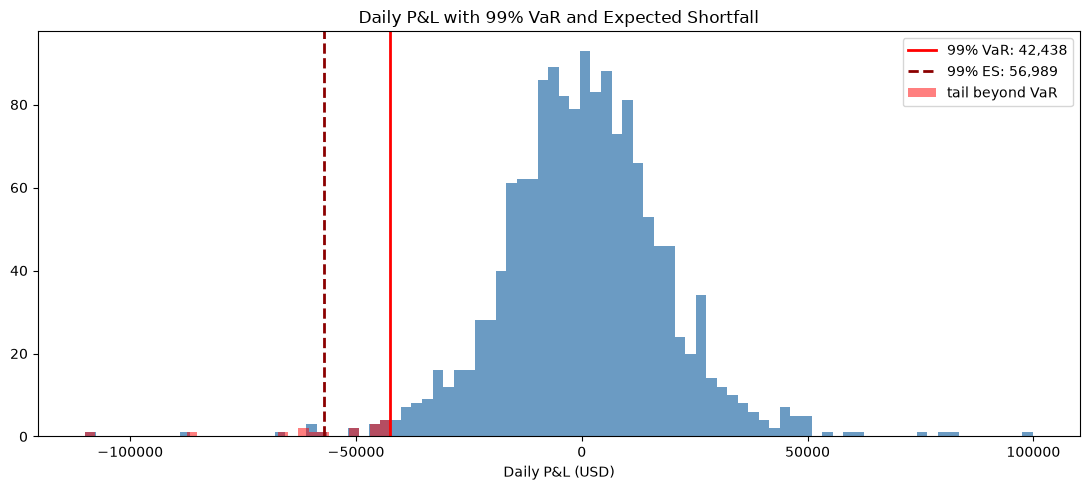

In [8]:
import matplotlib.pyplot as plt

c = 0.99
v_h = historical_var(pnl, c)
es_h = historical_es(pnl, c)

fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(pnl, bins=90, color="steelblue", alpha=0.8)
ax.axvline(-v_h, color="red", lw=2, label=f"99% VaR: {v_h:,.0f}")
ax.axvline(-es_h, color="darkred", lw=2, ls="--", label=f"99% ES: {es_h:,.0f}")
# shade the tail beyond VaR
tail = pnl[pnl <= -v_h]
ax.hist(tail, bins=30, color="red", alpha=0.5, label="tail beyond VaR")
ax.set_title("Daily P&L with 99% VaR and Expected Shortfall")
ax.set_xlabel("Daily P&L (USD)")
ax.legend()
plt.tight_layout()
plt.show()


## Day 2 summary

We built the core risk engine on top of the Day 1 P&L:

1. **Historical VaR** — empirical percentile, no distribution assumed.
2. **Parametric VaR** — normal assumption, fast but tail-light.
3. **Monte Carlo VaR** — simulated correlated returns, generalizable.
4. **Expected Shortfall** — average tail loss, the FRTB-mandated measure.

The comparison table is where the insight lives: differences between methods
reveal whether the book has fatter tails than a normal model assumes.

**Day 3:** regulatory **backtesting** — comparing predicted VaR against realized
P&L day by day, counting exceptions, and applying the Basel traffic-light test.
